# 🌍 Data Visualization — Real-World Scenario Worksheet
### You are the analyst. Each task is a real situation with a *decision* at the end.

> **How this works**
> - Every task gives you a scenario, real-ish data, and a **question to answer with a chart**.
> - Don't just draw the chart — **pick the right one** and, in a comment, say what it tells you.
> - Fill in the `# YOUR CODE HERE` sections. Run each cell to check your output.
> - 🏆 Each task ends with a **"So what?"** — one sentence stating the insight, like a real analyst would tell their boss.


## ⚙️ Setup — Run This First

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
%matplotlib inline
sns.set_style('whitegrid')

---
## ☕ Task 1 — The Coffee Shop Owner

**Scenario:** You run a small coffee shop. You want to know **which days are busiest** so you can schedule more staff. Here are last week's cup sales.

**Your job:** Draw the chart that best compares days, and **highlight the two busiest days in a different colour** so the owner sees them instantly.

*(Hint: comparing categories → bar chart. To highlight, build a list of colours.)*

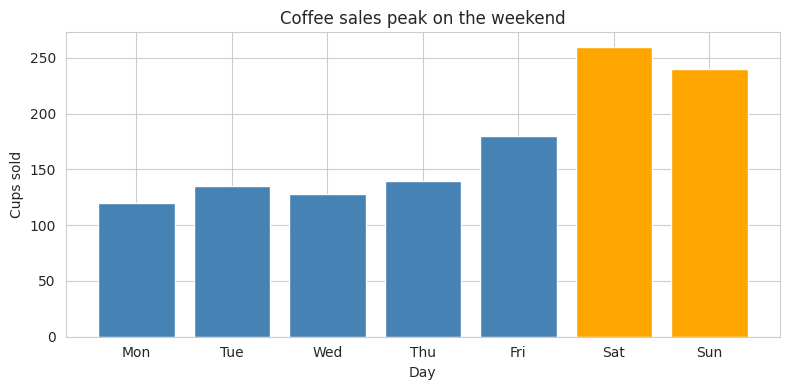

In [2]:
days = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']; cups = [120,135,128,140,180,260,240]
colors = ['steelblue']*5 + ['orange','orange']
plt.figure(figsize=(8,4)); plt.bar(days,cups,color=colors); plt.title('Coffee sales peak on the weekend'); plt.xlabel('Day'); plt.ylabel('Cups sold'); plt.tight_layout(); plt.show()
# The busiest days are Saturday and Sunday, so the owner should schedule more staff and stock.


---
## 🏃 Task 2 — The Fitness Tracker

**Scenario:** Your fitness app records daily steps. Your goal is **8,000 steps/day**. You want to see **which days you hit the goal and which you missed.**

**Your job:** Draw a line plot of steps over the week, then add a **horizontal goal line at 8,000** so misses are obvious at a glance.

*(Hint: change over time → line plot. Use `ax.axhline()` for the goal line.)*

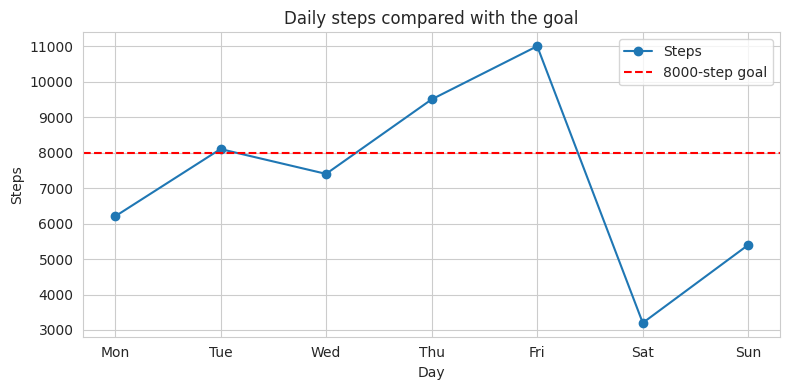

In [3]:
days=['Mon','Tue','Wed','Thu','Fri','Sat','Sun']; steps=[6200,8100,7400,9500,11000,3200,5400]
plt.figure(figsize=(8,4)); plt.plot(days,steps,marker='o',label='Steps'); plt.axhline(8000,color='red',linestyle='--',label='8000-step goal'); plt.title('Daily steps compared with the goal'); plt.xlabel('Day'); plt.ylabel('Steps'); plt.legend(); plt.tight_layout(); plt.show()
# Missed the goal on Monday, Wednesday, Saturday, and Sunday.


---
## 📱 Task 3 — The Streaming Report (Pick the Right Chart!)

**Scenario:** A streaming service wants to show **how many hours were watched per genre**. A junior designer made a **pie chart** — but there are 6 genres with similar values, so it's unreadable.

**Your job:** Prove the point. Draw the **pie chart (the bad version)** AND a **sorted horizontal bar chart (the good version)** side by side. Then, in a comment, say which one answers *"which genre is #1?"* faster.

*(Hint: `plt.subplots(1, 2)`. Sort the data before the bar chart.)*

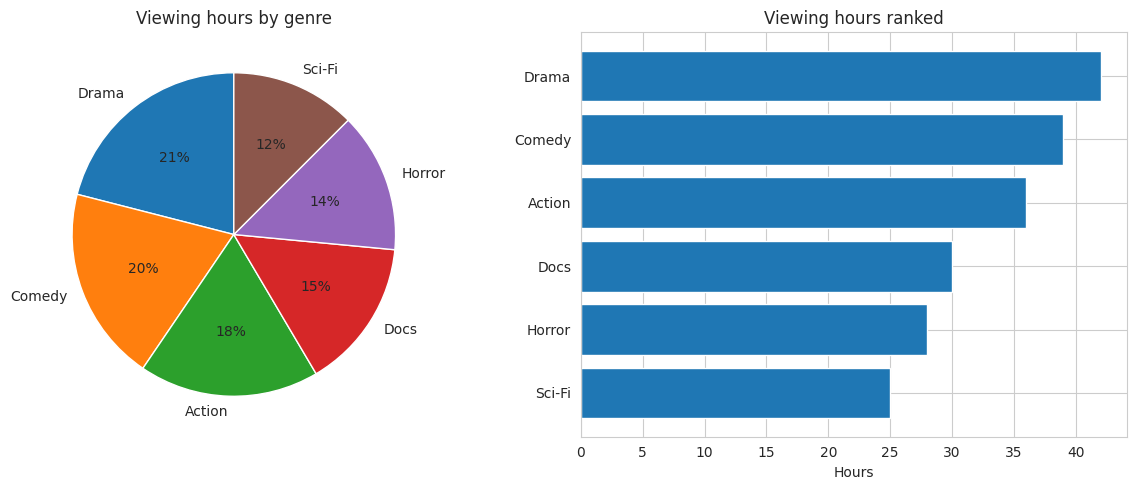

In [4]:
genres=['Drama','Comedy','Action','Docs','Horror','Sci-Fi']; hours=[42,39,36,30,28,25]
fig,axes=plt.subplots(1,2,figsize=(12,5)); axes[0].pie(hours,labels=genres,autopct='%1.0f%%',startangle=90); axes[0].set_title('Viewing hours by genre')
order=np.argsort(hours); axes[1].barh(np.array(genres)[order],np.array(hours)[order]); axes[1].set_title('Viewing hours ranked'); axes[1].set_xlabel('Hours'); plt.tight_layout(); plt.show()
# The sorted horizontal bar chart makes the ranking obvious because bar lengths are easy to compare.


---
## 🎓 Task 4 — Does Studying Actually Help? (Relationship)

**Scenario:** A school wants to know if **more study hours really lead to higher exam scores**, or if it's a myth.

**Your job:** Draw a **scatter plot** of study hours vs exam score. Then use Seaborn's `regplot` to add a **trend line** so the relationship is clear.

*(Hint: relationship between two numbers → scatter. `sns.regplot` adds the line for you.)*

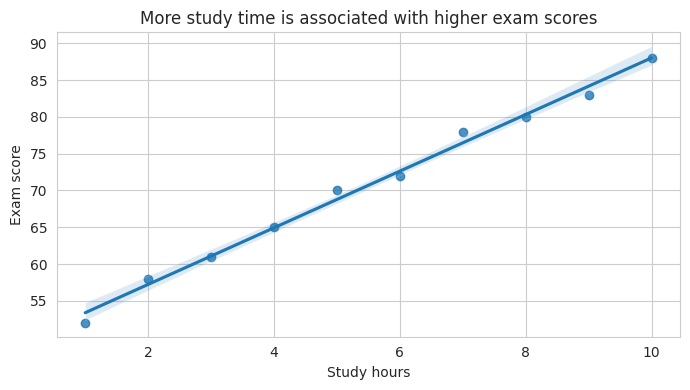

In [5]:
study_hours=[1,2,3,4,5,6,7,8,9,10]; exam_score=[52,58,61,65,70,72,78,80,83,88]
plt.figure(figsize=(7,4)); sns.regplot(x=study_hours,y=exam_score); plt.title('More study time is associated with higher exam scores'); plt.xlabel('Study hours'); plt.ylabel('Exam score'); plt.tight_layout(); plt.show()
# The relationship is positive: scores generally rise as study hours increase.


---
## 🍽️ Task 5 — The Restaurant Manager (Seaborn EDA)

**Scenario:** You manage a restaurant and want to know **when customers tip best**, so you can schedule your best servers then. Use the built-in `tips` dataset.

**Your job:** Build a **heatmap of average tip by day and time (Lunch/Dinner)**. The brightest cell is your money slot.

*(Hint: `pivot_table` to get day × time → tip, then `sns.heatmap(..., annot=True)`.)*

/tmp/ipykernel_775/685236111.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot=tips.pivot_table(index='day',columns='time',values='tip',aggfunc='mean'); print(pivot)


time     Lunch    Dinner
day                     
Thur  2.767705  3.000000
Fri   2.382857  2.940000
Sat        NaN  2.993103
Sun        NaN  3.255132


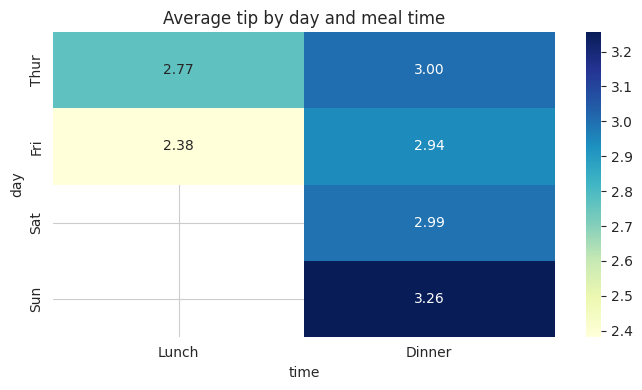

In [6]:
tips=sns.load_dataset('tips')
pivot=tips.pivot_table(index='day',columns='time',values='tip',aggfunc='mean'); print(pivot)
plt.figure(figsize=(7,4)); sns.heatmap(pivot,annot=True,fmt='.2f',cmap='YlGnBu'); plt.title('Average tip by day and meal time'); plt.tight_layout(); plt.show()
# Identify the highest cell from the printed pivot table/heatmap.


---
## 📈 Task 6 — The Startup Pitch (Interactive Plotly)

**Scenario:** You're pitching investors and want an **interactive** chart they can hover over. Using the `gapminder` dataset, show **how life expectancy relates to income**, and let them **watch it change over the years.**

**Your job:** Build a Plotly **animated scatter plot**: `gdpPercap` (x, log scale) vs `lifeExp` (y), bubble size = population, colour = continent, animation frame = year.

*(Hint: `px.scatter(..., animation_frame='year', log_x=True, size='pop', color='continent')`.)*

In [7]:
gapminder=px.data.gapminder()
fig=px.scatter(gapminder,x='gdpPercap',y='lifeExp',animation_frame='year',log_x=True,size='pop',color='continent',hover_name='country',size_max=55,title='GDP per capita and life expectancy over time')
fig.show()
# Overall, life expectancy generally rises over time as GDP per capita increases, though countries vary.


---
## 🛒 Task 7 — CAPSTONE: The E-Commerce Dashboard (Your Judgment)

**Scenario:** You're the data analyst for an online store. The founder asks for a **one-glance dashboard** of last week's performance. Below is the data.

**Your job:** Build a **2×2 dashboard** (`plt.subplots(2, 2)`). *You* choose the 4 charts — but you must pick the **right chart for each question** and write *why* in a comment above each.

Answer these 4 questions, one per subplot:
1. How did **daily revenue trend** across the week?
2. How do **orders compare** across days?
3. Is there a **relationship between orders and revenue**?
4. What **share of revenue** came from each product category? *(few categories → pie is OK here)*


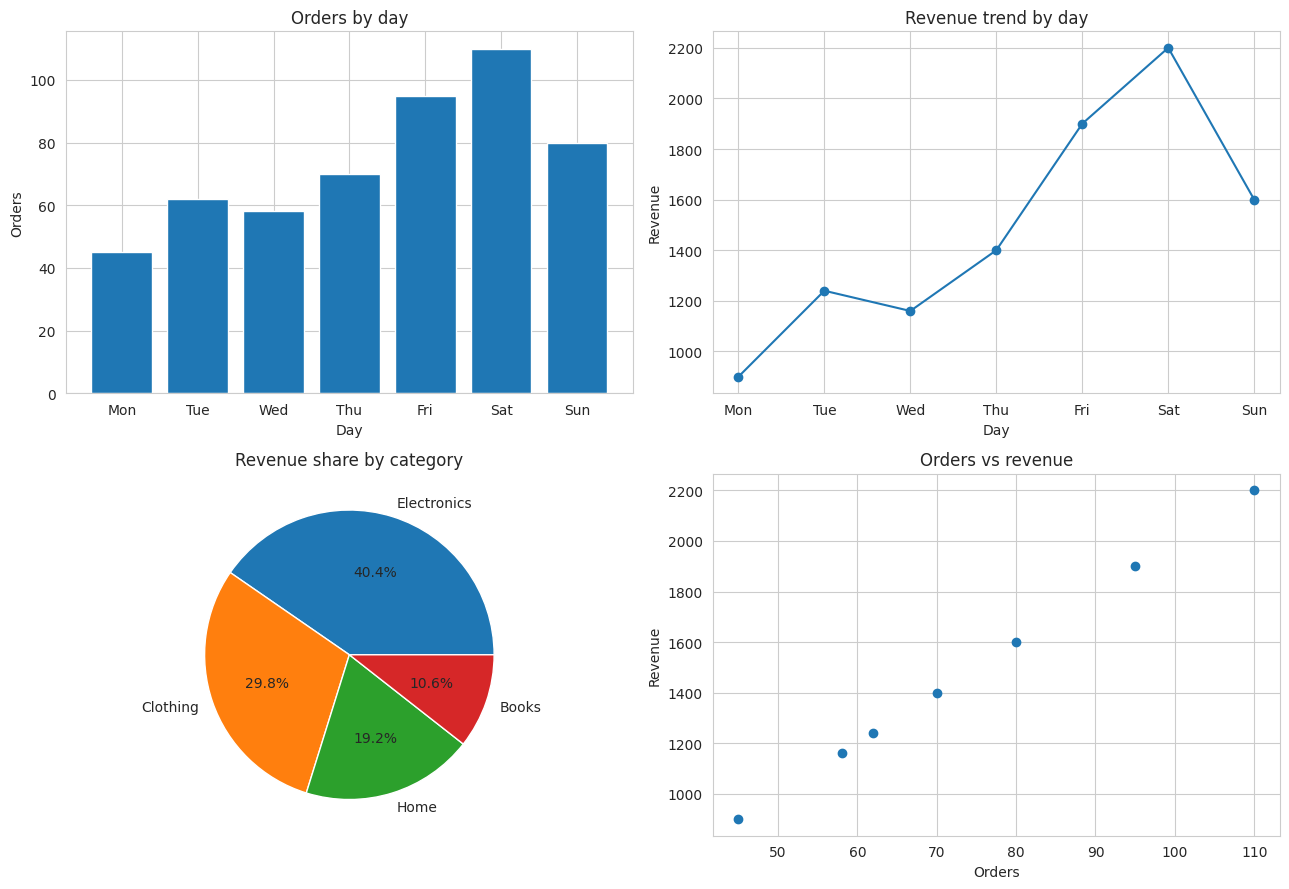

In [8]:
df=pd.DataFrame({'Day':['Mon','Tue','Wed','Thu','Fri','Sat','Sun'],'Orders':[45,62,58,70,95,110,80],'Revenue':[900,1240,1160,1400,1900,2200,1600]})
cat_names=['Electronics','Clothing','Home','Books']; cat_revenue=[4200,3100,2000,1100]
fig,axes=plt.subplots(2,2,figsize=(13,9))
axes[0,0].bar(df['Day'],df['Orders']); axes[0,0].set_title('Orders by day'); axes[0,0].set_xlabel('Day'); axes[0,0].set_ylabel('Orders')
axes[0,1].plot(df['Day'],df['Revenue'],marker='o'); axes[0,1].set_title('Revenue trend by day'); axes[0,1].set_xlabel('Day'); axes[0,1].set_ylabel('Revenue')
axes[1,0].pie(cat_revenue,labels=cat_names,autopct='%1.1f%%'); axes[1,0].set_title('Revenue share by category')
axes[1,1].scatter(df['Orders'],df['Revenue']); axes[1,1].set_title('Orders vs revenue'); axes[1,1].set_xlabel('Orders'); axes[1,1].set_ylabel('Revenue')
plt.tight_layout(); plt.show()


---
## 🤔 Wrap-Up Reflection
Answer as comments in the cell below.
1. For each task, did the *question* point you to the chart before you looked at the data? That's the skill.
2. In Task 3, why did the sorted bar chart beat the pie chart?
3. Name one chart from this worksheet where **starting the y-axis at zero** matters, and one where it doesn't.
4. In the capstone, which of your 4 charts was hardest to choose, and why?


In [9]:
# Q1:
# Q2:
# Q3:
# Q4:
